# Matched-filter peak detection demo

This notebook simulates a small set of TESS-like candidate light curves, loads the default precomputed self-lensing template library, and searches the candidates in one batch with `searchlight.matched_filtering.detect_matched_filter_peaks_batched`. The candidate systems cover the same broad parameter range as the template library, but deliberately do not use the exact template parameters.

In [1]:
from pathlib import Path
import sys


def find_project_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / "pyproject.toml").exists() and (path / "searchlight").exists():
            return path
    raise RuntimeError("Could not find the astrosearchlight project root")


project_root = find_project_root()
self_lensing_src = project_root.parent / "py-self-lensing" / "src"
if self_lensing_src.exists() and str(self_lensing_src) not in sys.path:
    sys.path.insert(0, str(self_lensing_src))

from astropy import units
from astropy.time import Time
from astropy.visualization import quantity_support

from matplotlib import pyplot

import numpy

try:
    from selflensing.generators import LightcurveGenerator
except ImportError as exc:
    raise ImportError(
        "This notebook requires py-self-lensing. Run "
        "`uv sync --extra template-generation --all-groups`, or keep the "
        "sibling py-self-lensing checkout next to this repo."
    ) from exc
from searchlight.matched_filtering import (
    DEFAULT_TEMPLATE_LIBRARY_PATH,
    detect_matched_filter_peaks_batched,
    load_template_library,
)
from selflensing.models import SelfLensingSystem

In [2]:
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x7f0de849c2f0>

## Simulate candidate light curves to search

In real use, `time` and `flux` would come from observed light curves. Here we generate a few synthetic candidates with light noise so the expected event times are known. Their parameters sit between the template-bank grid points rather than matching them exactly.

In [3]:
start_time = Time("2025-01-01")
end_time = Time("2025-01-27")
tess_bins = 27 * 24 * 6

tess_cadence = ((end_time.jd - start_time.jd) / (tess_bins - 1)) * units.day
candidate_specs = [
    {"a": 6.0, "Macc": 4.7, "Mcomp": 0.95, "peak_time": Time("2025-01-09")},
    {"a": 35.0, "Macc": 8.0, "Mcomp": 1.05, "peak_time": Time("2025-01-14")},
    {"a": 80.0, "Macc": 9.2, "Mcomp": 1.08, "peak_time": Time("2025-01-20")},
]

rng = numpy.random.default_rng(42)

candidate_lightcurves = []
for spec in candidate_specs:
    system = SelfLensingSystem(
        a=spec["a"] * units.AU,
        i=(0.5 * numpy.pi) * units.rad,
        Macc=spec["Macc"] * units.M_sun,
        Mcomp=spec["Mcomp"] * units.M_sun,
        e=0 * units.dimensionless_unscaled,
        d=1 * units.kpc,
    )
    lcg = LightcurveGenerator(
        system,
        start_time=start_time,
        end_time=end_time,
        peak_time=spec["peak_time"],
        ev=True,
        db=True,
        sl=True,
        bins=tess_bins,
    )
    flux = numpy.asarray(lcg.flux_array, dtype=float)
    flux = flux / numpy.nanmedian(flux)
    flux = flux + rng.normal(0.0, 0.001, size=len(flux))
    label = (
        f"a={spec['a']} AU, Macc={spec['Macc']} Msun, "
        f"Mcomp={spec['Mcomp']} Msun"
    )
    candidate_lightcurves.append(
        {
            "label": label,
            "times": lcg.times,
            "flux": flux,
            "peak_time": spec["peak_time"],
        }
    )

[(candidate["label"], candidate["peak_time"].iso) for candidate in candidate_lightcurves]

[('a=6.0 AU, Macc=4.7 Msun, Mcomp=0.95 Msun', '2025-01-09 00:00:00.000'),
 ('a=35.0 AU, Macc=8.0 Msun, Mcomp=1.05 Msun', '2025-01-14 00:00:00.000'),
 ('a=80.0 AU, Macc=9.2 Msun, Mcomp=1.08 Msun', '2025-01-20 00:00:00.000')]

Text(0.5, 0, 'Time [JD]')

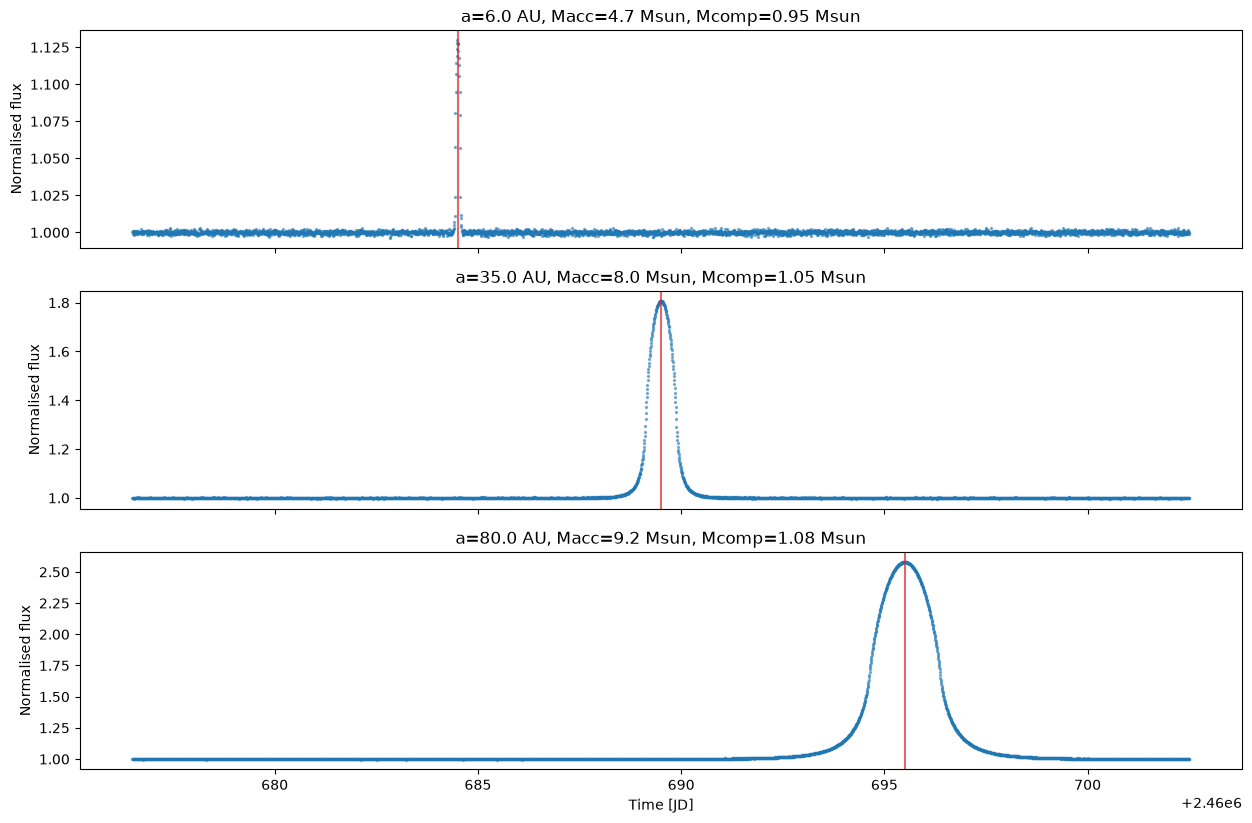

In [4]:
fig, axes = pyplot.subplots(
    len(candidate_lightcurves),
    1,
    figsize=(15, 3.2 * len(candidate_lightcurves)),
    sharex=True,
)
if len(candidate_lightcurves) == 1:
    axes = [axes]

for ax, candidate in zip(axes, candidate_lightcurves):
    ax.scatter(candidate["times"].jd, candidate["flux"], s=2, alpha=0.5, c="tab:blue")
    ax.axvline(candidate["peak_time"].jd, color="tab:red", alpha=0.7)
    ax.set_ylabel("Normalised flux")
    ax.set_title(candidate["label"])

axes[-1].set_xlabel("Time [JD]")

## Load the default template library

The matched-filter module can load a precomputed self-lensing template library from `data/matched_filter_templates.npz`. Generate it from the project root with:

```shell
uv sync --extra template-generation --all-groups
uv run python bin/generate_matched_filter_template_library.py
```

In [5]:
template_library_path = project_root / DEFAULT_TEMPLATE_LIBRARY_PATH
if not template_library_path.exists():
    raise FileNotFoundError(
        f"Template library not found at {template_library_path}. "
        "Generate it with bin/generate_matched_filter_template_library.py."
    )

template_library = load_template_library(template_library_path)
print(f"Loaded {len(template_library):,} templates from {template_library_path}")
print(f"Flux array shape: {template_library.flux.shape}")
print(
    f"Template time range: {template_library.time[0]:.3f} to "
    f"{template_library.time[-1]:.3f} days"
)
template_library.metadata

Loaded 55,392 templates from /home/anm1u24/Code/astrosearchlight/data/matched_filter_templates.npz
Flux array shape: (55392, 737)
Template time range: -30.654 to 30.680 days


{'cadence_minutes': 120.0,
 'half_window_days': 30.653792580972002,
 'window_scale': 1.2,
 'samples_per_parameter': None,
 'include_distance': False,
 'distance_samples': 1,
 'include_self_lensing': True,
 'include_ellipsoidal_variations': True,
 'include_doppler_boosting': True,
 'max_eccentricity': 0.999,
 'allow_rlof': False,
 'min_flux': 0.0,
 'skipped_invalid_flux': 0,
 'filter_interface': 'jax.vmap',
 'filter_batch_size': 65536,
 'generation_batch_size': 512,
 'generation_interface': 'selflensing.batch.make_batched_light_curve_generator',
 'grid_preset': 'completeness',
 'parameter_values': {'a': None,
  'i': None,
  'Macc': None,
  'Mcomp': None,
  'e': None,
  'periapsis_phase': None},
 'grid_size_before_filters': 74088,
 'grid_size_after_filters': 55392,
 'calibration': {'target_recall': 0.9,
  'validation': {'sample_count': 1000,
   'seed': 2372966673,
   'cadence_minutes': 120.0,
   'half_window_days': 27.234559340884747,
   'window_scale': 1.2,
   'include_distance': False,

In [6]:
template_parameters = template_library.parameters


def template_label(index):
    if template_parameters is None:
        return f"template {index}"
    row = template_parameters[index]
    fields = []
    for name in ("a", "Macc", "Mcomp", "e", "i"):
        if name in row.dtype.names:
            if name == "e":
                fields.append(f"{name}={row[name]:.6f}")
            else:
                fields.append(f"{name}={row[name]:.3g}")
    return f"{index}: " + ", ".join(fields)


template_labels = [template_label(index) for index in range(len(template_library))]
sample_indices = numpy.unique(
    numpy.linspace(0, len(template_library) - 1, min(12, len(template_library)), dtype=int)
)

[(template_labels[index], len(template_library.flux[index])) for index in sample_indices]

[('0: a=0.1, Macc=0.5, Mcomp=0.5, e=0.000000, i=1.57', 737),
 ('5035: a=0.2, Macc=0.5, Mcomp=10, e=0.600000, i=1.57', 737),
 ('10071: a=0.5, Macc=0.5, Mcomp=5, e=0.000000, i=1.57', 737),
 ('15106: a=1, Macc=5, Mcomp=10, e=0.800000, i=1.57', 737),
 ('20142: a=1, Macc=20, Mcomp=20, e=0.800000, i=1.57', 737),
 ('25177: a=3, Macc=0.5, Mcomp=0.5, e=0.800000, i=1.57', 737),
 ('30213: a=10, Macc=1, Mcomp=0.5, e=0.150000, i=1.57', 737),
 ('35248: a=30, Macc=1, Mcomp=20, e=0.600000, i=1.57', 737),
 ('40284: a=30, Macc=2, Mcomp=0.5, e=0.000000, i=1.57', 737),
 ('45319: a=100, Macc=10, Mcomp=0.5, e=0.150000, i=1.57', 737),
 ('50355: a=200, Macc=50, Mcomp=5, e=0.150000, i=1.57', 737),
 ('55391: a=200, Macc=50, Mcomp=50, e=0.930000, i=1.57', 737)]

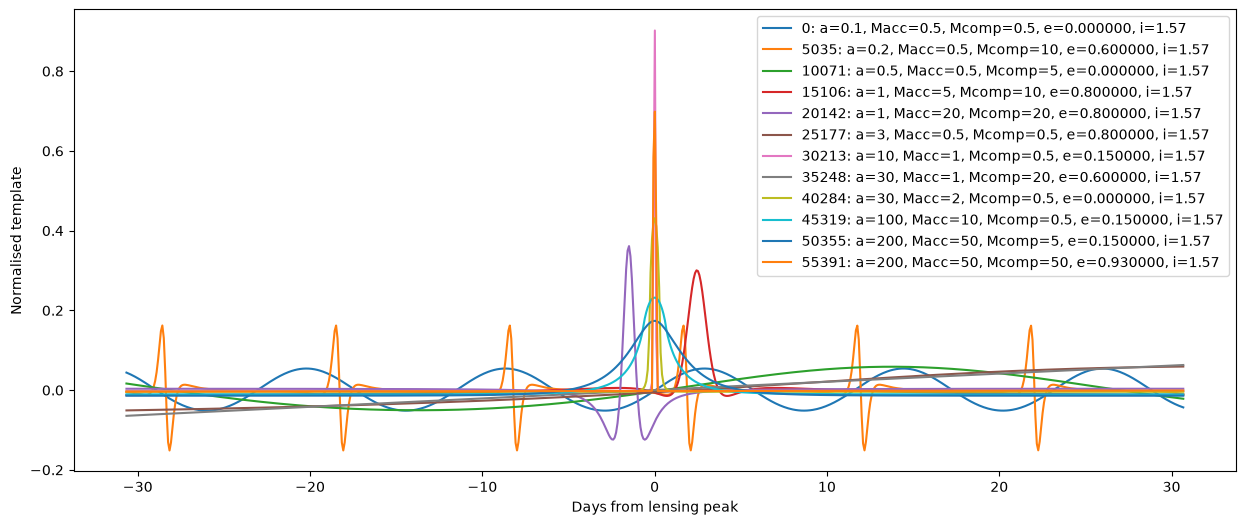

In [7]:
pyplot.figure(figsize=(15, 6))
for index in sample_indices:
    template_flux = template_library.flux[index]
    template_flux = template_flux - numpy.mean(template_flux)
    template_flux = template_flux / numpy.sqrt(numpy.sum(template_flux**2))
    pyplot.plot(template_library.time, template_flux, label=template_labels[index])
pyplot.xlabel("Days from lensing peak")
pyplot.ylabel("Normalised template")
pyplot.legend()

## Run the batched matched-filter search

`detect_matched_filter_peaks_batched` handles the shared template library load, mean subtraction, template normalisation, valid cross-correlation, and `scipy.signal.find_peaks` call for all candidate light curves on the shared time grid. The returned windows are mapped back onto the input light-curve timestamps.

In [8]:
candidate_times = candidate_lightcurves[0]["times"]
candidate_flux = numpy.stack([
    candidate["flux"] for candidate in candidate_lightcurves
])

candidate_results = detect_matched_filter_peaks_batched(
    candidate_times,
    candidate_flux,
    template_library,
    max_matches=3,
    batch_size=len(candidate_lightcurves),
    match_window_rel_height=0.5,
)

for candidate_index, (candidate, matches) in enumerate(zip(candidate_lightcurves, candidate_results)):
    print(f"candidate={candidate_index} ({candidate['label']}), expected_peak={candidate['peak_time'].jd:.5f}")
    if not matches:
        print("  no matches")
    for match in matches:
        print(
            f"  template={match.template_index} ({template_labels[match.template_index]}): "
            f"start={match.start_time:.5f}, "
            f"peak={match.peak_time:.5f}, "
            f"end={match.end_time:.5f}, "
            f"score={match.score:.5g}, "
            f"prominence={match.prominence:.5g}"
        )

candidate=0 (a=6.0 AU, Macc=4.7 Msun, Mcomp=0.95 Msun), expected_peak=2460684.50000
  template=54112 (54112: a=200, Macc=5, Mcomp=10, e=0.930000, i=1.57): start=2460684.42584, peak=2460684.49331, end=2460684.55768, score=0.46845, prominence=0.4736
candidate=1 (a=35.0 AU, Macc=8.0 Msun, Mcomp=1.05 Msun), expected_peak=2460689.50000
  template=45582 (45582: a=100, Macc=10, Mcomp=20, e=0.150000, i=1.57): start=2460689.05441, peak=2460689.50334, end=2460689.94712, score=7.1513, prominence=7.5186
candidate=2 (a=80.0 AU, Macc=9.2 Msun, Mcomp=1.08 Msun), expected_peak=2460695.50000
  template=51183 (51183: a=200, Macc=2, Mcomp=10, e=0.600000, i=1.57): start=2460694.32542, peak=2460695.49666, end=2460696.65548, score=20.577, prominence=22.566


Text(0.5, 0, 'Time [JD]')

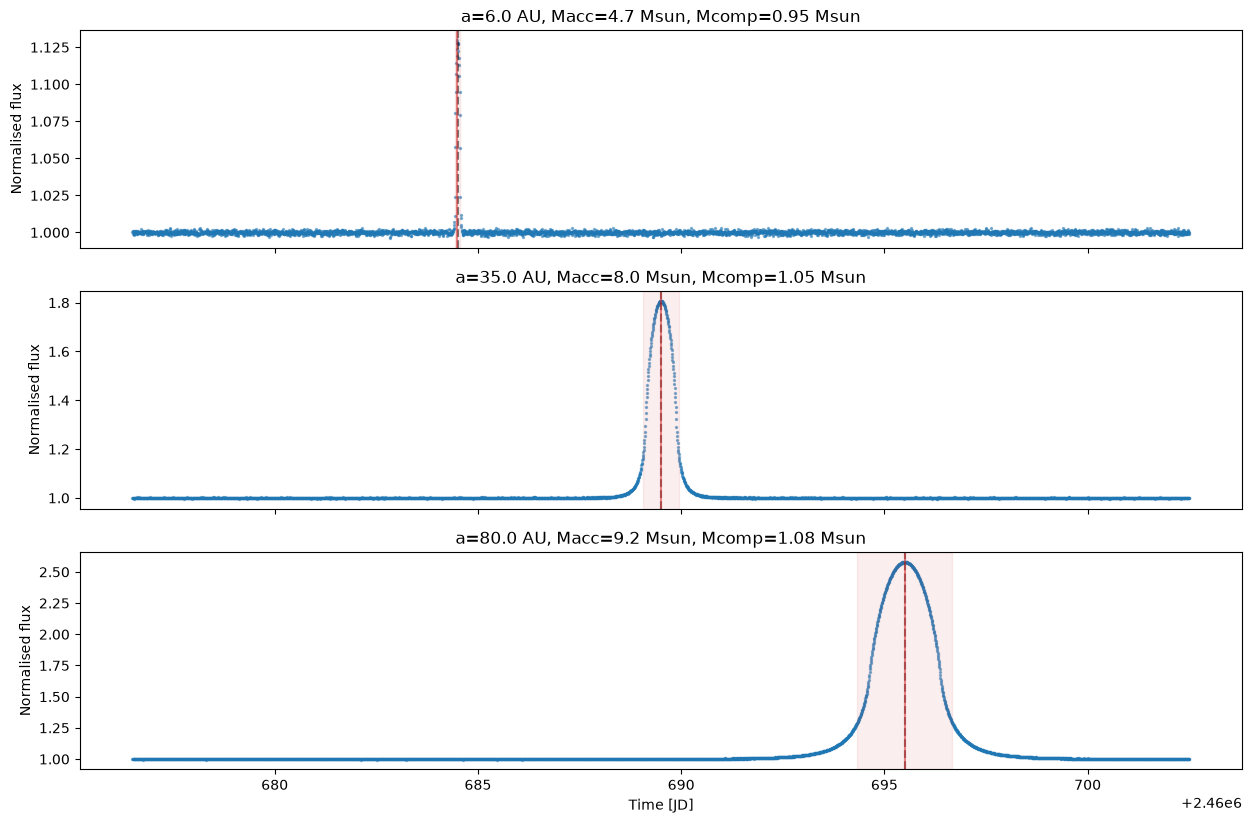

In [9]:
fig, axes = pyplot.subplots(
    len(candidate_lightcurves),
    1,
    figsize=(15, 3.2 * len(candidate_lightcurves)),
    sharex=True,
)
if len(candidate_lightcurves) == 1:
    axes = [axes]

for ax, candidate, matches in zip(axes, candidate_lightcurves, candidate_results):
    ax.scatter(candidate["times"].jd, candidate["flux"], s=2, alpha=0.5, c="tab:blue")
    ax.axvline(candidate["peak_time"].jd, color="black", linestyle="--", alpha=0.5)

    for match in matches:
        ax.axvspan(match.start_time, match.end_time, color="tab:red", alpha=0.08)
        ax.axvline(match.peak_time, color="tab:red", alpha=0.55)

    ax.set_ylabel("Normalised flux")
    ax.set_title(candidate["label"])

axes[-1].set_xlabel("Time [JD]")